# SMOTE-ENN for Data Augmentation in steel classification

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.combine import SMOTEENN
import matplotlib.pyplot as plt

<br>

## 1. Load and prepare data

In [3]:
# Read labeled_OES_data_2.csv
data = pd.read_csv("labeled_OES_data_2.csv")

# convert steel types to numbers
# Note: in our project steel types are not predefined, but will be extracted from the supplied file of data
classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")
data = data.map(pd.to_numeric)
data.dtypes

C              float64
Si             float64
Mn             float64
P              float64
S              float64
Cr             float64
Ni             float64
Al             float64
Cu             float64
steel_class      int64
dtype: object

## 2. Split Data

In [6]:
X = data.iloc[:, :-1] 
y = data.iloc[:, -1]   

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:\n", X_train.head())
print("y_train:\n", y_train.head())
print("y_train types:\n", y_train.dtypes)

X_train:
              C        Si        Mn         P         S        Cr        Ni  \
306   0.212333  0.148667  0.710167  0.025033  0.051967  0.066517  0.068783   
1139  0.173000  0.511833  1.020000  0.021300  0.037750  0.341333  0.099983   
31    0.291000  0.231000  0.665000  0.023000  0.042000  0.006000  0.051000   
210   0.210000  0.268667  0.547333  0.016300  0.037067  0.044467  0.067700   
924   0.228333  0.005033  0.784000  0.025750  0.029933  0.005000  0.032917   

            Al        Cu  
306   0.002000  0.189833  
1139  0.054183  0.407667  
31    0.002000  0.188000  
210   0.002000  0.133333  
924   0.002100  0.051383  
y_train:
 306     0
1139    0
31      0
210     0
924     3
Name: steel_class, dtype: int64
y_train types:
 int64


<br>

## 3. Resample with SMOTE-ENN

In [101]:
smote_enn = SMOTEENN(random_state=42)
X_resampled, y_resampled = smote_enn.fit_resample(X_train, y_train)

In [102]:
resampled_data = pd.concat([X_resampled, y_resampled], axis=1)
print(resampled_data)

             C        Si        Mn         P         S        Cr        Ni  \
0     0.212333  0.148667  0.710167  0.025033  0.051967  0.066517  0.068783   
1     0.173000  0.511833  1.020000  0.021300  0.037750  0.341333  0.099983   
2     0.291000  0.231000  0.665000  0.023000  0.042000  0.006000  0.051000   
3     0.210000  0.268667  0.547333  0.016300  0.037067  0.044467  0.067700   
4     0.211333  0.309833  0.659333  0.021533  0.042283  0.032600  0.121000   
...        ...       ...       ...       ...       ...       ...       ...   
3148  0.004274  0.072987  0.130739  0.073287  0.002000  0.005000  0.011904   
3149  0.005779  0.131894  0.240000  0.170000  0.015744  0.005000  0.032221   
3150  0.180249  0.105351  0.145627  0.054329  0.002920  0.005000  0.025000   
3151  0.003000  0.100269  0.129188  0.170000  0.034838  0.009838  0.030081   
3152  0.003000  0.237111  0.497901  0.103778  0.002099  0.002099  0.008397   

            Al        Cu  steel_class  
0     0.002000  0.18983

<br>

## 4. Save resampled data to file

In [103]:
#resampled_data.to_csv("resampled_steel_data.csv", index=False)

print("Original training dataset shape:", X_train.shape, y_train.shape)
print("Resampled training dataset shape:", X_resampled.shape, y_resampled.shape)


Original training dataset shape: (1143, 9) (1143,)
Resampled training dataset shape: (3153, 9) (3153,)


<br>

## 5. Comparison between original and resampled data

<br>

### Steel type distributions

In [104]:
grouped_data = data.groupby("steel_class")
number_of_samples_group = []

for group_id, gdata in grouped_data:
    for key, val in classes_dict.items():
        if val == group_id:
            group_name = key
    print("Group Name:", group_name)
    print(gdata.shape)
    number_of_samples_group.append(gdata.shape[0])

Group Name: St 48
(827, 10)
Group Name: St 37
(247, 10)
Group Name: St Si
(79, 10)
Group Name: St 48-TH
(71, 10)
Group Name: Puddelstahl
(205, 10)


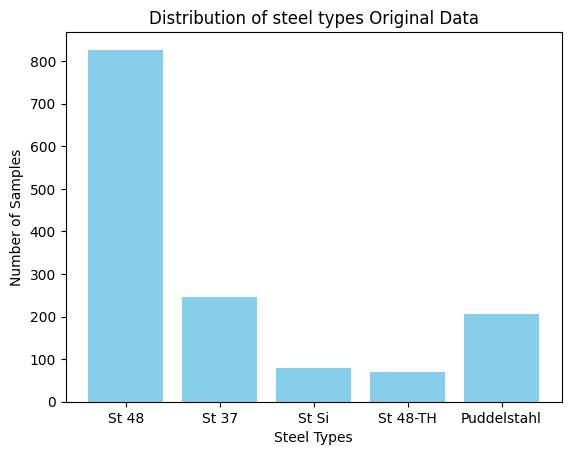

In [105]:
steel_type_names = classes_dict.keys()

plt.bar(steel_type_names, number_of_samples_group, color='skyblue')

plt.xlabel('Steel Types')
plt.ylabel('Number of Samples')
plt.title('Distribution of steel types Original Data')

#plt.savefig('Distribution_of_steel_types_Original_Data.jpg', format='jpg')
plt.show()

In [106]:
grouped_data = resampled_data.groupby("steel_class")
number_of_samples_group = []

for group_id, gdata in grouped_data:
    for key, val in classes_dict.items():
        if val == group_id:
            group_name = key
    print("Group Name:", group_name)
    print(gdata.shape)
    number_of_samples_group.append(gdata.shape[0])

Group Name: St 48
(622, 10)
Group Name: St 37
(615, 10)
Group Name: St Si
(660, 10)
Group Name: St 48-TH
(595, 10)
Group Name: Puddelstahl
(661, 10)


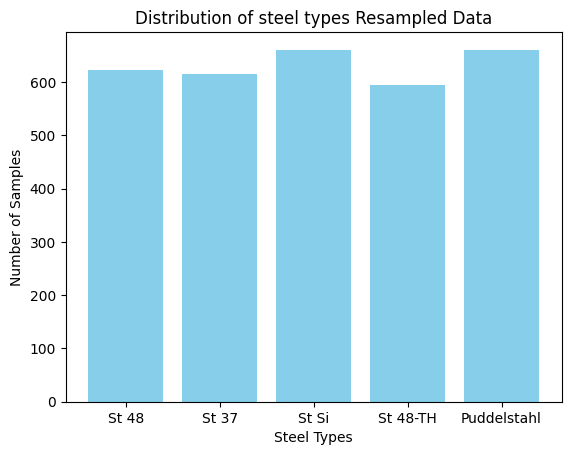

In [107]:
steel_type_names = classes_dict.keys()

plt.bar(steel_type_names, number_of_samples_group, color='skyblue')

plt.xlabel('Steel Types')
plt.ylabel('Number of Samples')
plt.title('Distribution of steel types Resampled Data')

#plt.savefig('Distribution_of_steel_types_Resampled_Data.jpg', format='jpg')
plt.show()

<br>

### Vizualization of Data

In [108]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
import numpy as np

In [109]:
scaler = StandardScaler()
pca = PCA(3)

scaled_training_data = scaler.fit_transform(X)
pca_training_data = pca.fit_transform(scaled_training_data)
pca_training_data

array([[ 1.67142614,  1.00098842, -2.00602227],
       [ 0.76505056, -0.48361338,  0.49208704],
       [ 1.10293241, -0.45347383, -0.18911143],
       ...,
       [-2.9951984 , -1.54557045,  0.13843373],
       [-2.83364725, -0.12533926,  0.23516999],
       [-2.86551898, -0.43271864,  0.46717795]])

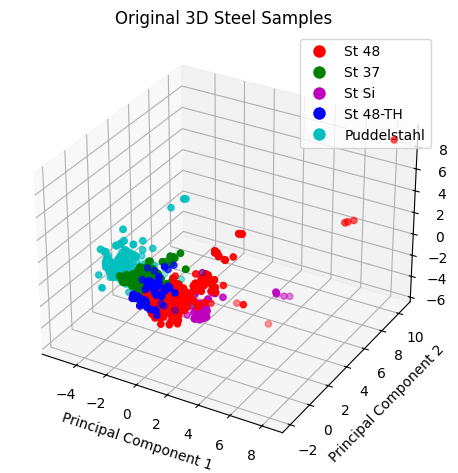

In [110]:
x_tr = pca_training_data[:, 0]
y_tr = pca_training_data[:, 1]
z_tr = pca_training_data[:, 2]

rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}


class_colors = ['r', 'g', 'm', 'b', 'c']
classes = [0, 1, 2, 3, 4]
categories = y


fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x_tr)):
        ax.scatter(x_tr[i], y_tr[i], z_tr[i], c=class_colors[categories.iloc[i]], label=f'Category {categories.iloc[i]}', alpha=0.1)

legend_elements = []
for i in range(len(class_colors)):
    if i in classes:
        indices = np.where(categories == i)[0]
        ax.scatter(x_tr[indices], y_tr[indices], z_tr[indices], c=class_colors[i], label= rev_classes_dict[i])
        legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=class_colors[i], markersize=10, label= rev_classes_dict[i]))

ax.legend(handles=legend_elements, loc='upper right')

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('Original 3D Steel Samples')
plt.tight_layout()
plt.savefig('ENN_Original_Data_3D.jpg', format='jpg')
plt.show()


In [111]:
scaled_training_data = scaler.fit_transform(resampled_data.iloc[:, :-1])
pca_training_data = pca.fit_transform(scaled_training_data)
pca_training_data

array([[ 2.18600298, -0.54998823,  1.80260287],
       [ 7.8361994 ,  5.36648157,  8.56084371],
       [ 1.3048519 , -1.36354404, -0.04507487],
       ...,
       [-2.48296544, -0.27172775,  0.2787485 ],
       [-3.0532926 ,  1.54319863,  0.08903737],
       [-2.52078779,  1.33733464, -0.76780962]])

3153   3153


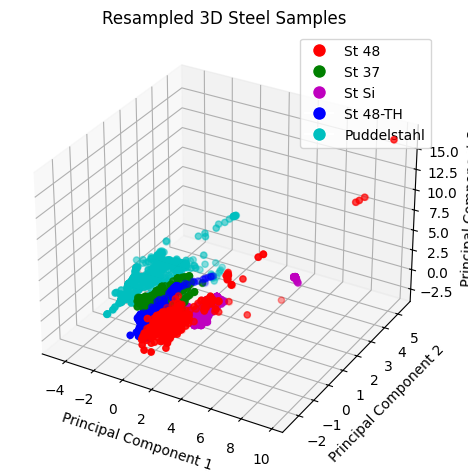

In [112]:
x_tr = pca_training_data[:, 0]
y_tr = pca_training_data[:, 1]
z_tr = pca_training_data[:, 2]

rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}


class_colors = ['r', 'g', 'm', 'b', 'c']
classes = [0, 1, 2, 3, 4]
categories = resampled_data.iloc[:, -1]


fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
print(len(x_tr), " ", len(categories))
for i in range(len(x_tr)):
        ax.scatter(x_tr[i], y_tr[i], z_tr[i], c=class_colors[categories.iloc[i]], label=f'Category {categories.iloc[i]}', alpha=0.1)


legend_elements = []
for i in range(len(class_colors)):
    if i in classes:
        indices = np.where(categories == i)[0]
        ax.scatter(x_tr[indices], y_tr[indices], z_tr[indices], c=class_colors[i], label= rev_classes_dict[i])
        legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=class_colors[i], markersize=10, label= rev_classes_dict[i]))

ax.legend(handles=legend_elements, loc='upper right')

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('Resampled 3D Steel Samples')
plt.tight_layout()
plt.savefig('ENN_Resampled_Data_3D.jpg', format='jpg')

plt.show()
